<a href="https://colab.research.google.com/github/wilson-luu/econ3916-midterm-project/blob/main/midterm_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 Midterm Project — Econometric Foundation

**ECON 3916 · Applied Data Analytics** · Topics 1-14 · 100 points · your role: Independent analyst

This is the **starter**: the structure of the project in rubric order. Fill the empty cells and keep every heading so the grader finds each section. The brief on Canvas has the full text of every section and the rubric. The grader reruns this notebook from the top, so every number, table and figure in your report must come from a cell here.

**🛑 This project is entirely NO AI.** Not phases one to three — all of it. No AI for the code, the analysis, the writing, or the editing. This is the one assessment in the course that establishes you can do the work unaided, and it is the one you will draw on when an interviewer asks what you built. Everything you have practised with a co-pilot, you do here alone.

## Start here

Work top to bottom. What each part of this notebook is for:

1. **Data provenance**: where the file came from. It feeds Section 1 and your README.
2. **Section 1**: load the data into a DataFrame called `df`, then run the *Section 1 self-check* cell and answer the questions under it. Do this before the **Mon 2 Nov** checkpoint.
3. **Section 2**: figures, each with a caption that states a finding.
4. **Section 3**: the OLS model, with a draft committed by **Fri 6 Nov**.
5. **Section 4**: diagnostics, only after Topic 14.
6. **Section 5**: words only.
7. **Numbers my report quotes**: last. Every number in the report must be printed there.

The brief's *Six checks before you post* list the problems that came up most often in Checkpoint 1. Read them before you settle on your controls.

## Setup

Imports only. Add any others you need here, at the top.

In [14]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["figure.dpi"] = 110

## Data provenance

Fill these in when you download the data. They feed Section 1 and your README.

In [15]:
SOURCE_URL = "https://databank.worldbank.org/source/world-development-indicators"
DOWNLOAD_DATE = "2026-11-01"
FILE_NAME = "project-data.csv"
GITHUB_RAW_URL = "https://raw.githubusercontent.com/wilson-luu/midterm-project/refs/heads/main/project-data.csv"

**Who collected it, for what purpose, what is missing and why?**

The World Bank collected this data for the World Development Indicators (WDI) to track global economic development and provide comparable cross-country indicators. Five series were downloaded for 217 economies across 1999–2021 (1999 is included solely to construct the one-year lag of real GDP per capita for the year 2000): applied tariff rate, simple mean across all products (TM.TAX.MRCH.SM.AR.ZS), total trade as a share of GDP (NE.TRD.GNFS.ZS), total population (SP.POP.TOTL), total natural resource rents as a share of GDP (NY.GDP.TOTL.RT.ZS), and real GDP per capita in constant 2015 US$ (NY.GDP.PCAP.KD).

In the reshaped 2000-2021 dataset (4,774 country-years across 217 economies), applied tariff rates are missing in 1,593 country-years, comprising 29 economies that never report tariffs in any year (638 country-years, mostly territories and microstates such as Andorra, American Samoa, Gibraltar, etc.) plus 955 intermittent gaps among reporting countries. Trade is missing in 855 country-years, including 24 economies with zero reported years (such as Nigeria, Jamaica, and Trinidad and Tobago). Additionally, Venezuela reports 0.0 for trade (% of GDP) across all 12 years from 2000 to 2011, which becomes undefined under a natural log, yielding 867 missing values in log_trade. Natural resource rents are missing in 239 country-years and lagged log GDP per capita in 236 country-years.

Because missingness depends strongly on observed country size and median income, country-years without tariff data have a much smaller median population (0.76 million vs. 8.75 million; mean log population 13.73 vs. 15.81) and a lower median real GDP per capita (4,406.60 vs. 5,961.58, though mean GDP per capita is slightly higher at 17,466.36 vs. 14,575.51 due to tiny wealthy territories), this gap is not MCAR and is best labeled Missing at Random (MAR) conditional on observed covariates.

## Section 1: The Question and the Data (20 pts)

State the question in one sentence, and say why it matters and to whom. Describe the data as a product of measurement decisions, name the missingness mechanism (MCAR, MAR or MNAR) and defend the label. Build a summary-statistics table a reader can read without asking you a question.

In [16]:
# Load raw WDI export (supports local repo file or direct GitHub URL in Colab)
if os.path.exists(FILE_NAME):
    df_raw = pd.read_csv(FILE_NAME, na_values=["..", ""])
elif os.path.exists(os.path.join("data", FILE_NAME)):
    df_raw = pd.read_csv(os.path.join("data", FILE_NAME), na_values=["..", ""])
else:
    df_raw = pd.read_csv(GITHUB_RAW_URL, na_values=["..", ""])

# Drop WDI footer/metadata rows at the bottom of the CSV
df_raw = df_raw.dropna(subset=["Country Code", "Series Code"]).copy()
RAW_ROWS, RAW_COLS = df_raw.shape

# Melt wide year columns into long country-series-year format
year_cols = [c for c in df_raw.columns if "[YR" in c]
df_melt = df_raw.melt(
    id_vars=["Country Name", "Country Code", "Series Name", "Series Code"],
    value_vars=year_cols,
    var_name="Year_Str",
    value_name="Value"
)
df_melt["Year"] = df_melt["Year_Str"].str[:4].astype(int)

# Pivot the five WDI series into columns (one row per country-year)
df_all = df_melt.pivot(
    index=["Country Name", "Country Code", "Year"],
    columns="Series Code",
    values="Value"
).reset_index()
df_all.columns.name = None

df_all.rename(columns={
    "NE.TRD.GNFS.ZS": "trade_gdp",
    "TM.TAX.MRCH.SM.AR.ZS": "tariff_rate",
    "SP.POP.TOTL": "population",
    "NY.GDP.TOTL.RT.ZS": "resource_rents",
    "NY.GDP.PCAP.KD": "gdppc"
}, inplace=True)

for col in ["trade_gdp", "tariff_rate", "population", "resource_rents", "gdppc"]:
    df_all[col] = pd.to_numeric(df_all[col], errors="coerce")

df_all = df_all.sort_values(["Country Code", "Year"]).reset_index(drop=True)

# Construct logs safely (values <= 0 become NaN without divide-by-zero warnings)
df_all["log_trade"] = np.log(df_all["trade_gdp"].where(df_all["trade_gdp"] > 0))
df_all["log_pop"] = np.log(df_all["population"].where(df_all["population"] > 0))
df_all["log_gdppc"] = np.log(df_all["gdppc"].where(df_all["gdppc"] > 0))

# Build 1-year lag of GDP per capita strictly within each country
df_all["lag_gdppc"] = df_all.groupby("Country Code")["gdppc"].shift(1)
df_all["lag_log_gdppc"] = df_all.groupby("Country Code")["log_gdppc"].shift(1)
df_all["Country_Code"] = df_all["Country Code"]

# Restrict to 2000-2021 analysis window (1999 only supplied the lag for 2000)
df = df_all[df_all["Year"] >= 2000].copy()

# Inspect zero trade_gdp observations in 2000-2021
zero_trade_rows = df[df["trade_gdp"] <= 0]
print(f"Raw WDI table (excluding footer): {RAW_ROWS:,} rows x {RAW_COLS} columns")
print(f"Reshaped 1999-2021 panel: {len(df_all):,} rows x {df_all.shape[1]} columns")
print(f"Non-positive trade_gdp rows in 2000-2021 set to NaN before logging: {len(zero_trade_rows)} "
      f"({zero_trade_rows['Country Name'].unique().tolist()}, "
      f"{int(zero_trade_rows['Year'].min())}-{int(zero_trade_rows['Year'].max())})")

Raw WDI table (excluding footer): 1,085 rows x 27 columns
Reshaped 1999-2021 panel: 4,991 rows x 14 columns
Non-positive trade_gdp rows in 2000-2021 set to NaN before logging: 12 (['Venezuela, RB'], 2000-2011)


In [17]:
# Section 1 self-check: run once your data is loaded into a DataFrame called df.
# It prints what Section 1 has to report. It doesn't judge your choices: answer the questions below.
UNIT = "country-year"        # one row is one what? e.g. "county" or "country-year"
OUTCOME = "log_trade"     # your dependent variable's column name
MAIN_X = "tariff_rate"      # your main explanatory variable's column name
CONTROLS = ["log_pop", "resource_rents", "lag_log_gdppc"]    # every other column in your model

if "df" in globals():
    print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   One row is: {UNIT or '(fill in UNIT)'}")
    cols = [c for c in [OUTCOME, MAIN_X, *CONTROLS] if c]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        print("Not in df:", absent)
    present = [c for c in cols if c in df.columns]
    if present:
        print("\nMissing values per column:")
        print(df[present].isna().sum().to_string())
    if OUTCOME in df.columns and pd.api.types.is_numeric_dtype(df[OUTCOME]):
        print(f"\nSkew of {OUTCOME}: {df[OUTCOME].skew():.2f} (above about 1, consider a log)")
        print(f"Skew of raw trade_gdp: {df['trade_gdp'].skew():.2f} (above 1 -> log transformation justified)")
else:
    print("Load your data into a DataFrame called df first, then run this cell.")

Rows: 4,774   Columns: 14   One row is: country-year

Missing values per column:
log_trade          867
tariff_rate       1593
log_pop              0
resource_rents     239
lag_log_gdppc      236

Skew of log_trade: 0.22 (above about 1, consider a log)
Skew of raw trade_gdp: 3.44 (above 1 -> log transformation justified)


In [18]:
# Missingness diagnostics (MAR check), Sample Attrition Table (Table 1), and Summary Statistics (Table 2)
all_miss_tariff = df.groupby("Country_Code")["tariff_rate"].apply(lambda s: s.isna().all())
all_miss_trade = df.groupby("Country_Code")["trade_gdp"].apply(lambda s: s.isna().all())
n_countries_all_miss_tariff = int(all_miss_tariff.sum())
n_countries_all_miss_trade = int(all_miss_trade.sum())

intermittent_tariff_miss = int(
    df.loc[df.groupby("Country_Code")["tariff_rate"].transform(lambda s: s.notna().any()), "tariff_rate"].isna().sum()
)

# MAR evidence: compare observed population & GDPpc for missing vs. non-missing tariffs
mar_check = df.assign(tariff_missing=df["tariff_rate"].isna()).groupby("tariff_missing").agg(
    country_years=("Country_Code", "count"),
    median_pop_m=("population", lambda s: s.median() / 1e6),
    mean_log_pop=("log_pop", "mean"),
    median_gdppc=("gdppc", "median"),
    mean_gdppc=("gdppc", "mean")
)
print("MAR Diagnostic — Missing vs. Observed Tariff Rate (2000-2021):")
print(mar_check.round(2).to_string())

# Sequential sample attrition (Table 1)
s0 = len(df_all)
s1 = len(df)
s2 = len(df.dropna(subset=["tariff_rate"]))
s3 = len(df.dropna(subset=["tariff_rate", "trade_gdp"]))
s4 = len(df.dropna(subset=["tariff_rate", "trade_gdp", "log_trade"]))
s5 = len(df.dropna(subset=["tariff_rate", "trade_gdp", "log_trade", "resource_rents"]))
model_vars = ["log_trade", "tariff_rate", "log_pop", "resource_rents", "lag_log_gdppc"]
df_sample = df.dropna(subset=model_vars).copy()
df_sample["pop_m"] = df_sample["population"] / 1e6
s6 = len(df_sample)

attrition_table = pd.DataFrame([
    ("Reshaped WDI panel (1999-2021, 217 economies)", s0, 0),
    ("Restrict to 2000-2021 (1999 used only for GDP lag)", s1, s1 - s0),
    ("Drop missing applied tariff rate", s2, s2 - s1),
    ("Drop missing trade (% of GDP)", s3, s3 - s2),
    ("Drop zero trade (% of GDP) — Venezuela 2000-2011", s4, s4 - s3),
    ("Drop missing natural resource rents (% of GDP)", s5, s5 - s4),
    ("Drop missing lagged log GDP per capita / population", s6, s6 - s5),
], columns=["Step", "Country-Years", "Change"])

print("\nTable 1. From 4,991 reshaped country-years to the final analysis sample")
print(attrition_table.to_string(index=False))

# Summary statistics on the final analysis sample (Table 2)
summary_spec = [
    ("Trade openness (% of GDP)", "trade_gdp"),
    ("Log trade openness (ln % of GDP)", "log_trade"),
    ("Applied tariff rate, simple mean (%)", "tariff_rate"),
    ("Population (millions)", "pop_m"),
    ("Log population (ln persons)", "log_pop"),
    ("Total natural resource rents (% of GDP)", "resource_rents"),
    ("Lagged real GDP per capita (2015 US$)", "lag_gdppc"),
    ("Lagged log real GDP per capita (ln 2015 US$)", "lag_log_gdppc"),
]
summary_table = pd.DataFrame([
    {
        "Variable (units)": label,
        "Mean": round(df_sample[col].mean(), 2),
        "Median": round(df_sample[col].median(), 2),
        "SD": round(df_sample[col].std(), 2),
        "Min": round(df_sample[col].min(), 2),
        "Max": round(df_sample[col].max(), 2),
        "N": int(df_sample[col].count()),
    }
    for label, col in summary_spec
])

print(f"\nTable 2. Summary statistics, {len(df_sample):,} country-years across {df_sample['Country_Code'].nunique()} economies, 2000-2021")
print(summary_table.to_string(index=False))
print("Source: World Bank World Development Indicators (downloaded 2026-11-01).")

MAR Diagnostic — Missing vs. Observed Tariff Rate (2000-2021):
                country_years  median_pop_m  mean_log_pop  median_gdppc  mean_gdppc
tariff_missing                                                                     
False                    3181          8.75         15.81       5961.58    14575.51
True                     1593          0.76         13.73       4406.60    17466.36

Table 1. From 4,991 reshaped country-years to the final analysis sample
                                               Step  Country-Years  Change
      Reshaped WDI panel (1999-2021, 217 economies)           4991       0
 Restrict to 2000-2021 (1999 used only for GDP lag)           4774    -217
                   Drop missing applied tariff rate           3181   -1593
                      Drop missing trade (% of GDP)           2866    -315
   Drop zero trade (% of GDP) — Venezuela 2000-2011           2854     -12
     Drop missing natural resource rents (% of GDP)           2841     -13
Dro

**Answer before you go on.**

1. For each control: does your main explanatory variable change it? If yes, it is on the path from X to Y. Drop it, or run with and without and say what each version measures.

    - Lagged log real GDP per capita (lag_log_gdppc): Measured in year t - 1, strictly prior to the current tariff rate in year t, so year t tariffs cannot cause year t - 1 income.

    - Log population (log_pop): Tariff schedules do not materially change a nation's population size in the short run. However, because country fixed effects already absorb baseline country size and population moves very slowly within a country over 22 years, I estimate the model both with and without log_pop in Section 3 to illustrate the difference.

    - Natural resource rents (resource_rents, % of GDP): Geological endowments are exogenous to tariff policy, though because the denominator is GDP, an extreme tariff shock that shrinks non-resource GDP could marginally shift the ratio. Running specifications with and without controls clarifies its role.

2. Are all your variables in the same units and for the same years?

    - Yes, every row is one country-year on the identical 2000-2021 panel (1999 is used to compute the 2000 value of lag_log_gdppc). Income is measured consistently in constant 2015 US$ across all economies, and trade, tariffs, and resource rents are all measured in percentage-point shares.

3. If your question is about a policy, where is the period before it?

    - This project evaluates a continuous policy variable (tariff rate) in a cross-country panel over 22 years, rather than a single event study, so there is no single period before it. Country and year fixed effects exploit within-country tariff changes over time relative to global annual trends.

A foundational principle of macroeconomics is that free trade drives efficiency, yet nations continuously utilize tariffs to protect domestic industries. Understanding whether high applied tariff rates directly correlate with constrained overall trade openness matters to trade policymakers and international organizations assessing the impact of protectionist policies.

My question is: Across countries from 2000 to 2021, how much lower is trade openness associated with higher average applied import tariffs, controlling for country size, natural-resource dependence, income, and country and year fixed effects? The dependent variable is the natural log of trade (exports plus imports as a percentage of GDP), and the main explanatory variable is the simple mean applied tariff rate across all products (%). I hypothesize a negative association because tariffs raise the domestic price of imported goods and inputs, dampening import demand and indirectly taxing export competitiveness.

The data are a product of measurement decisions by the World Bank. Simple mean applied tariffs weight every tariff line equally and exclude non-tariff barriers such as quotas or licensing rules. Trade (% of GDP) captures gross goods and services flows relative to value-added GDP, allowing entrepôt hubs such as Hong Kong SAR (peaking at 442.62% in 2013) and Singapore (437.33% in 2008) to exceed 100%. Furthermore, Venezuela records exactly 0.0% trade for 2000-2011. Treating these 12 zero entries as missing avoids undefined logs and reduces the complete-case sample from 2,853 to 2,841 country-years across 173 economies (Table 1 and Table 2).

## Section 2: Descriptive Evidence (20 pts)

Show the reader the data before any model. At least two figures, each with a caption that states its finding, not its variables. Chapter 3's standards for axes. If the outcome is skewed, show it and say what you will do about it.

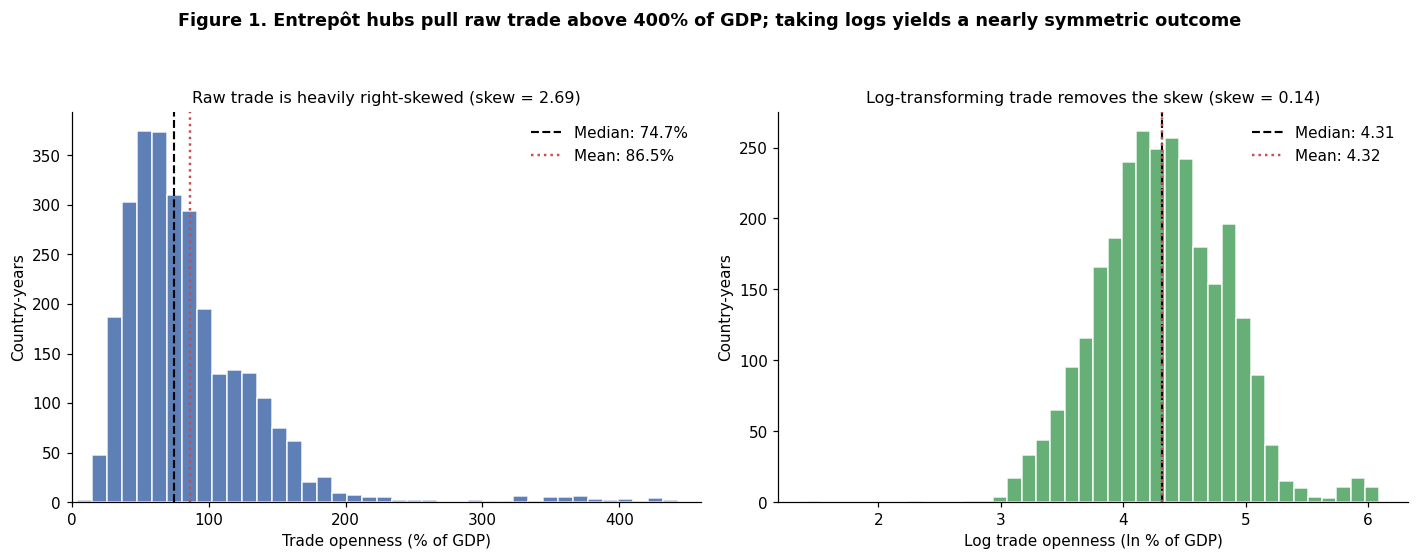

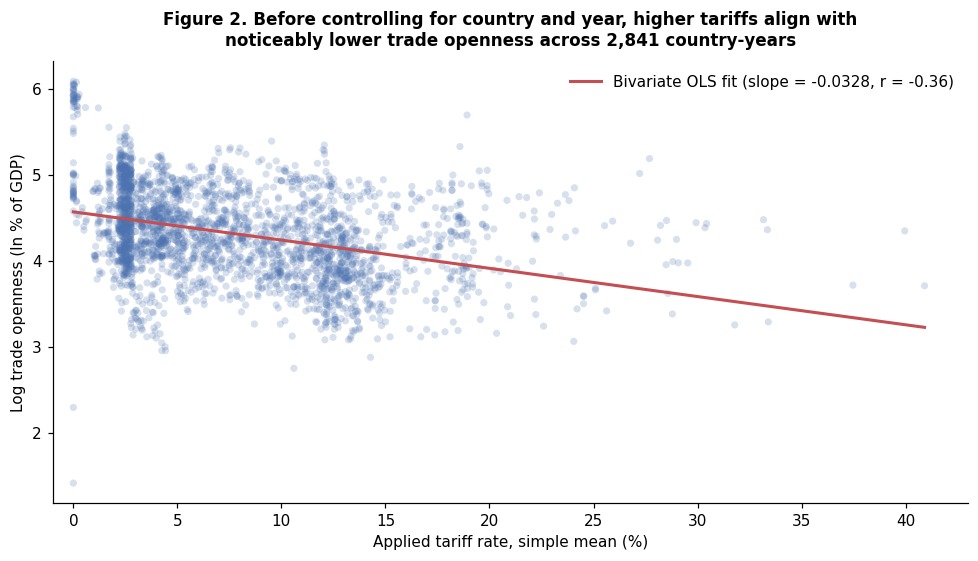

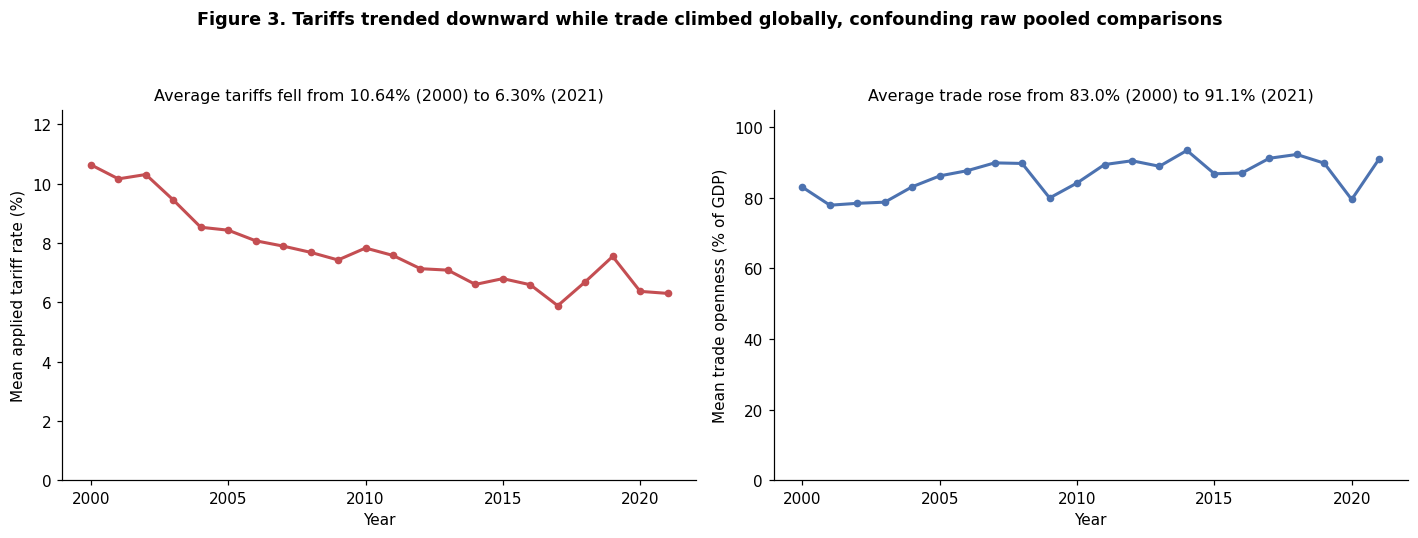

In [19]:
# Figure 1: Raw Trade (% of GDP) skewness vs. Log Trade symmetry
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

raw_skew = df_sample["trade_gdp"].skew()
log_skew = df_sample["log_trade"].skew()
med_trade = df_sample["trade_gdp"].median()
mean_trade = df_sample["trade_gdp"].mean()
med_log_trade = df_sample["log_trade"].median()
mean_log_trade = df_sample["log_trade"].mean()

axes[0].hist(df_sample["trade_gdp"], bins=40, color="#4C72B0", edgecolor="white", alpha=0.9)
axes[0].axvline(med_trade, color="black", linestyle="--", linewidth=1.4, label=f"Median: {med_trade:.1f}%")
axes[0].axvline(mean_trade, color="#C44E52", linestyle=":", linewidth=1.6, label=f"Mean: {mean_trade:.1f}%")
axes[0].set_xlabel("Trade openness (% of GDP)")
axes[0].set_ylabel("Country-years")
axes[0].set_xlim(0, 460)
axes[0].legend(frameon=False)
axes[0].set_title(f"Raw trade is heavily right-skewed (skew = {raw_skew:.2f})", fontsize=10.5)

axes[1].hist(df_sample["log_trade"], bins=40, color="#55A868", edgecolor="white", alpha=0.9)
axes[1].axvline(med_log_trade, color="black", linestyle="--", linewidth=1.4, label=f"Median: {med_log_trade:.2f}")
axes[1].axvline(mean_log_trade, color="#C44E52", linestyle=":", linewidth=1.6, label=f"Mean: {mean_log_trade:.2f}")
axes[1].set_xlabel("Log trade openness (ln % of GDP)")
axes[1].set_ylabel("Country-years")
axes[1].legend(frameon=False)
axes[1].set_title(f"Log-transforming trade removes the skew (skew = {log_skew:.2f})", fontsize=10.5)

fig.suptitle(
    "Figure 1. Entrepôt hubs pull raw trade above 400% of GDP; taking logs yields a nearly symmetric outcome",
    y=0.97, fontsize=11.5, fontweight="bold"
)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

# Figure 2: Raw scatter of Log Trade vs. Applied Tariff Rate with bivariate OLS line
raw_corr = df_sample["tariff_rate"].corr(df_sample["log_trade"])
slope_raw, intercept_raw = np.polyfit(df_sample["tariff_rate"], df_sample["log_trade"], 1)
x_grid = np.linspace(df_sample["tariff_rate"].min(), df_sample["tariff_rate"].max(), 200)

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.scatter(df_sample["tariff_rate"], df_sample["log_trade"], alpha=0.22, s=22, color="#4C72B0", edgecolors="none")
ax.plot(x_grid, intercept_raw + slope_raw * x_grid, color="#C44E52", linewidth=2,
        label=f"Bivariate OLS fit (slope = {slope_raw:.4f}, r = {raw_corr:.2f})")
ax.set_xlabel("Applied tariff rate, simple mean (%)")
ax.set_ylabel("Log trade openness (ln % of GDP)")
ax.set_xlim(-1, 43)
ax.legend(frameon=False)
ax.set_title(
    "Figure 2. Before controlling for country and year, higher tariffs align with\nnoticeably lower trade openness across 2,841 country-years",
    fontsize=11, fontweight="bold", pad=10
)
plt.tight_layout()
plt.show()

# Figure 3: Global time trends (2000-2021) showing why year fixed effects matter
yearly = df_sample.groupby("Year").agg(
    mean_tariff=("tariff_rate", "mean"),
    mean_trade=("trade_gdp", "mean"),
    mean_log_trade=("log_trade", "mean"),
    n_countries=("Country_Code", "count")
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 5.0))

axes[0].plot(yearly["Year"], yearly["mean_tariff"], marker="o", markersize=4, color="#C44E52", linewidth=2)
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Mean applied tariff rate (%)")
axes[0].set_ylim(0, 12.5)
axes[0].set_title(
    f"Average tariffs fell from {yearly.loc[yearly['Year']==2000, 'mean_tariff'].values[0]:.2f}% (2000) "
    f"to {yearly.loc[yearly['Year']==2021, 'mean_tariff'].values[0]:.2f}% (2021)",
    fontsize=10.5
)

axes[1].plot(yearly["Year"], yearly["mean_trade"], marker="o", markersize=4, color="#4C72B0", linewidth=2)
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Mean trade openness (% of GDP)")
axes[1].set_ylim(0, 105)
axes[1].set_title(
    f"Average trade rose from {yearly.loc[yearly['Year']==2000, 'mean_trade'].values[0]:.1f}% (2000) "
    f"to {yearly.loc[yearly['Year']==2021, 'mean_trade'].values[0]:.1f}% (2021)",
    fontsize=10.5
)

fig.suptitle(
    "Figure 3. Tariffs trended downward while trade climbed globally, confounding raw pooled comparisons",
    y=0.97, fontsize=11.5, fontweight="bold"
)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

Before fitting any regression, three visual patterns shape the empirical specification:

- Figure 1 shows that raw trade openness (% of GDP) is heavily right-skewed (skewness = 2.69): the median country-year sits at 74.71% of GDP, well below the mean of 86.46%, because entrepôt hubs stretch the upper tail past 400%. Taking the natural log cuts the skewness to 0.14 (median 4.31 vs. mean 4.32), stabilizing variance and letting coefficients be read cleanly as approximate percentage changes.

- Figure 2 shows a clear negative raw relationship before adding any controls: across all 2,841 pooled country-years, the correlation between applied tariff rates and log trade is -0.36, and a bivariate OLS line has a slope of -0.0328 (roughly 3.3% lower trade openness for each additional percentage point of tariffs).

- Figure 3 shows why that raw slope cannot be taken at face value. Between 2000 and 2021, mean applied tariffs fell steadily from 10.64% to 6.30%, while average trade openness climbed from 83.03% to 91.06% (with sharp global shocks during the 2009 financial crisis and the 2020 pandemic). Because trade and tariffs co-moved with global time trends and small, open, low-tariff economies differ structurally from large, high-tariff economies, country and year fixed effects are essential.

## Section 3: The Model (25 pts)

Fit a multivariate OLS model and report it in a formatted regression table (coefficients, standard errors, N, R-squared), not a `summary()` dump. Interpret at least two coefficients in full: magnitude, units, direction, precision. For every control, say whether it blocks a confounding path or adds precision, and what would make it a bad control (Chapter 10). OLS only: no difference-in-differences estimate.

In [20]:
# Estimate progressive specifications with country-clustered standard errors
f_biv = "log_trade ~ tariff_rate"
f_pool = "log_trade ~ tariff_rate + log_pop + resource_rents + lag_log_gdppc"
f_main = "log_trade ~ tariff_rate + log_pop + resource_rents + lag_log_gdppc + C(Country_Code) + C(Year)"
f_nopop = "log_trade ~ tariff_rate + resource_rents + lag_log_gdppc + C(Country_Code) + C(Year)"

m1_biv = smf.ols(f_biv, data=df_sample).fit(cov_type="cluster", cov_kwds={"groups": df_sample["Country_Code"]})
m2_pool = smf.ols(f_pool, data=df_sample).fit(cov_type="cluster", cov_kwds={"groups": df_sample["Country_Code"]})
res = smf.ols(f_main, data=df_sample).fit(cov_type="cluster", cov_kwds={"groups": df_sample["Country_Code"]})
m4_nopop = smf.ols(f_nopop, data=df_sample).fit(cov_type="cluster", cov_kwds={"groups": df_sample["Country_Code"]})

# Also fit classical and HC1 versions of the main model for Section 4 diagnostics
res_classical = smf.ols(f_main, data=df_sample).fit()
res_hc1 = smf.ols(f_main, data=df_sample).fit(cov_type="HC1")

def format_reg_table(models, col_names, vars_to_show):
    rows = []
    for var_key, var_label in vars_to_show:
        coef_row = {"Variable": var_label}
        se_row = {"Variable": ""}
        for m, cname in zip(models, col_names):
            if var_key in m.params:
                coef_row[cname] = f"{m.params[var_key]:.4f}"
                se_row[cname] = f"({m.bse[var_key]:.4f})"
            else:
                coef_row[cname] = ""
                se_row[cname] = ""
        rows.extend([coef_row, se_row])
    fe_c = {"Variable": "Country fixed effects"}
    fe_y = {"Variable": "Year fixed effects"}
    n_row = {"Variable": "N (country-years)"}
    r2_row = {"Variable": "R-squared"}
    for m, cname in zip(models, col_names):
        has_fe = any("C(Country_Code)" in k for k in m.params.index)
        fe_c[cname] = "Yes" if has_fe else "No"
        fe_y[cname] = "Yes" if has_fe else "No"
        n_row[cname] = f"{int(m.nobs):,}"
        r2_row[cname] = f"{m.rsquared:.4f}"
    rows.extend([fe_c, fe_y, n_row, r2_row])
    return pd.DataFrame(rows)

vars_display = [
    ("tariff_rate", "Applied tariff rate (%)"),
    ("log_pop", "Log population"),
    ("resource_rents", "Natural resource rents (% GDP)"),
    ("lag_log_gdppc", "Lagged log real GDP per capita"),
]

reg_table_sec3 = format_reg_table(
    [m1_biv, m2_pool, res, m4_nopop],
    ["(1) Bivariate", "(2) Pooled + Controls", "(3) Main (FE)", "(4) FE, No Pop"],
    vars_display
)
print("Table 3. OLS estimates of log trade openness (% of GDP) on applied tariff rates, 2000-2021")
print(reg_table_sec3.to_string(index=False))
print("Note: Standard errors clustered by country (173 clusters) in parentheses. Country and year dummies omitted for brevity.")

# Print exact 95% confidence intervals for the main model
ci_main = res.conf_int()
print("\nMain Model (Column 3) 95% Confidence Intervals (Country-Clustered SE):")
for v in ["tariff_rate", "log_pop", "resource_rents", "lag_log_gdppc"]:
    print(f"  {v:15s}: coef = {res.params[v]:7.4f}, SE = {res.bse[v]:.4f}, "
          f"95% CI = [{ci_main.loc[v, 0]:7.4f}, {ci_main.loc[v, 1]:7.4f}], p = {res.pvalues[v]:.4f}")

Table 3. OLS estimates of log trade openness (% of GDP) on applied tariff rates, 2000-2021
                      Variable (1) Bivariate (2) Pooled + Controls (3) Main (FE) (4) FE, No Pop
       Applied tariff rate (%)       -0.0328               -0.0269       -0.0027        -0.0028
                                    (0.0065)              (0.0051)      (0.0037)       (0.0037)
                Log population                             -0.1308       -0.2895               
                                                          (0.0161)      (0.1173)               
Natural resource rents (% GDP)                              0.0033        0.0087         0.0100
                                                          (0.0022)      (0.0024)       (0.0023)
Lagged log real GDP per capita                              0.0371       -0.1896        -0.1464
                                                          (0.0248)      (0.0666)       (0.0671)
         Country fixed effects            No 

I estimate the following two-way fixed-effects OLS model on the 2000-2021 panel (2,841 country-years across 173 economies), with standard errors clustered by country to account for serial correlation across the 22 annual observations of each economy.

Comparing specifications (Table 3): Without fixed effects, higher tariffs strongly predict lower trade openness: -0.0328 (clustered SE 0.0065, R2 = 0.1268) in the bivariate regression (Column 1) and -0.0269 (SE 0.0051, R2 = 0.3695) with pooled controls (Column 2). Once country and year fixed effects enter the model (Column 3), R2 rises to 0.9258 and the tariff coefficient drops by an order of magnitude to -0.0027, showing that almost all of the raw cross-country slope reflects permanent differences between nations and shared global trends rather than within-country tariff changes.

Full coefficient interpretations (Main Model, Column 3):

- Applied tariff rate (coefficient = -0.0027, clustered SE = 0.0037, p = 0.4563): Holding country size, natural-resource dependence, lagged income, permanent country traits, and global year shocks fixed, a 1 percentage point increase in a country's simple mean applied tariff rate is associated with roughly 0.27% lower trade openness.

- Natural resource rents (coefficient = +0.0087, clustered SE = 0.0024, p = 0.0003): Holding tariffs, population, lagged income, and country and year fixed effects constant, a 1 percentage point increase in total natural resource rents as a share of GDP is associated with 0.87% higher trade openness. This reflects the mechanics of commodity exporters: when resource prices or extraction booms raise resource rents, merchandise exports surge relative to GDP.

- Lagged log real GDP per capita (coefficient = -0.1896, clustered SE = 0.0666, p = 0.0044): Holding other controls and fixed effects constant, a 10% higher prior-year real GDP per capita within a country is associated with roughly 1.90% lower trade as a share of GDP, consistent with domestic services and internal markets expanding faster than gross goods trade as countries grow richer.

Control roles and bad-control assessment:

- Country fixed effects and year fixed effects: Block unobserved time-invariant confounders (geography, landlocked status, colonial trade ties, institutional history) and global shocks (WTO rounds, the 2009 financial crisis, COVID-19). Neither can be caused by a single country's year t tariff rate, so neither is a bad control.

- Lagged log real GDP per capita: Blocks confounding from development level, wealthier economies typically levy lower tariffs and have different trade structures. Using contemporaneous GDP per capita would risk making income a bad control if tariffs reduce current-year GDP. Lagging by one year closes that contemporaneous path, though multi-year persistence in tariff regimes could still create dynamic feedback.

- Natural resource rents: Blocks confounding from commodity dependence (oil and mineral exporters often pair high trade shares with distinct tariff structures) and adds precision. It would become a bad control only if tariffs strongly altered the GDP denominator, such as shrinking non-resource GDP while resource extraction stayed fixed, or mechanically inflating rents/GDP.

- Log population: In pooled regressions (Column 2), population blocks a major confounder because large nations have bigger internal markets and trade less across borders. With country dummies included (Column 3), population changes very slowly within a country over 22 years, so its coefficient reflects within-country demographic growth rather than baseline size and is relatively noisy. Column 4 drops log_pop altogether: the tariff coefficient is almost identical (-0.0028, SE = 0.0037, R2 = 0.9240 vs. -0.0027, R2 = 0.9258), confirming that retaining log_pop to capture within-country market growth neither distorts nor drives the main finding.

## Section 4: Diagnostics (20 pts)

Residuals against fitted values and against your main predictor; a constant-variance check, with robust standard errors if it fails; variance inflation factors, interpreted; at least one influential-observation check.

**Start only after Topic 14.** Write Sections 1 to 3 first; they do not depend on it.

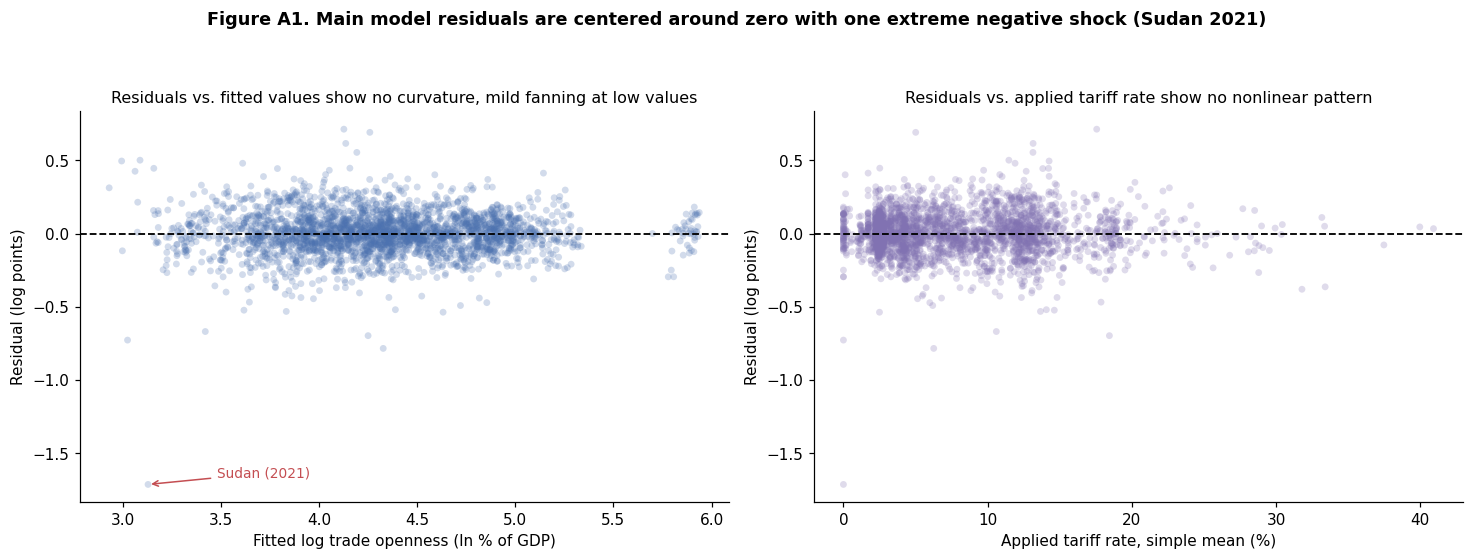

Linearity check (tariff_rate^2): coef = -0.000257, SE = 0.000238, p = 0.2792
Main model residual SD: 0.1465 log points

Breusch-Pagan test (Main FE model): LM = 721.87, p-value = 5.69e-61

Standard Error Comparison on Applied Tariff Rate:
                         Standard Error Type  Tariff Coef     SE  p-value  95% CI Low  95% CI High
       Classical OLS (homoskedastic, i.i.d.)      -0.0027 0.0013   0.0290     -0.0052      -0.0003
             Heteroskedasticity-robust (HC1)      -0.0027 0.0021   0.1953     -0.0069       0.0014
Country-clustered (Main model, 173 clusters)      -0.0027 0.0037   0.4563     -0.0099       0.0045

Variance Inflation Factors:
     Predictor  Pooled VIF (no FE)  Within-FE VIF (demeaned)  Full-Matrix VIF (with dummies)
   tariff_rate                1.50                      1.02                            6.59
       log_pop                1.04                      1.11                          592.88
resource_rents                1.04                      1

In [21]:
# 1. Residual plots (Figure A1) + Linearity check (quadratic term)
df_sample["fitted"] = res.fittedvalues
df_sample["residuals"] = res.resid
resid_sd = float(np.sqrt(res_classical.mse_resid))

# Identify largest residual outlier for clean annotation
max_resid_row = df_sample.loc[df_sample["residuals"].abs().idxmax()]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

axes[0].scatter(df_sample["fitted"], df_sample["residuals"], alpha=0.25, s=20, color="#4C72B0", edgecolors="none")
axes[0].axhline(0, color="black", linestyle="--", linewidth=1.2)
axes[0].annotate(
    f"{max_resid_row['Country Name']} ({int(max_resid_row['Year'])})",
    xy=(max_resid_row["fitted"], max_resid_row["residuals"]),
    xytext=(max_resid_row["fitted"] + 0.35, max_resid_row["residuals"] + 0.05),
    arrowprops=dict(arrowstyle="->", color="#C44E52", lw=1),
    fontsize=9, color="#C44E52"
)
axes[0].set_xlabel("Fitted log trade openness (ln % of GDP)")
axes[0].set_ylabel("Residual (log points)")
axes[0].set_title("Residuals vs. fitted values show no curvature, mild fanning at low values", fontsize=10.5)

axes[1].scatter(df_sample["tariff_rate"], df_sample["residuals"], alpha=0.25, s=20, color="#8172B2", edgecolors="none")
axes[1].axhline(0, color="black", linestyle="--", linewidth=1.2)
axes[1].set_xlabel("Applied tariff rate, simple mean (%)")
axes[1].set_ylabel("Residual (log points)")
axes[1].set_title("Residuals vs. applied tariff rate show no nonlinear pattern", fontsize=10.5)

fig.suptitle(
    "Figure A1. Main model residuals are centered around zero with one extreme negative shock (Sudan 2021)",
    y=0.97, fontsize=11.5, fontweight="bold"
)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

# Direct nonlinearity test: add tariff_rate^2
m_quad = smf.ols(
    "log_trade ~ tariff_rate + I(tariff_rate**2) + log_pop + resource_rents + lag_log_gdppc + C(Country_Code) + C(Year)",
    data=df_sample
).fit(cov_type="cluster", cov_kwds={"groups": df_sample["Country_Code"]})
print(f"Linearity check (tariff_rate^2): coef = {m_quad.params['I(tariff_rate ** 2)']:.6f}, "
      f"SE = {m_quad.bse['I(tariff_rate ** 2)']:.6f}, p = {m_quad.pvalues['I(tariff_rate ** 2)']:.4f}")
print(f"Main model residual SD: {resid_sd:.4f} log points")

# 2. Constant-variance check (Breusch-Pagan test) & Standard Error comparison
bp_lm, bp_pval, bp_f, bp_fpval = het_breuschpagan(res_classical.resid, res_classical.model.exog)
print(f"\nBreusch-Pagan test (Main FE model): LM = {bp_lm:.2f}, p-value = {bp_pval:.2e}")

se_comp = pd.DataFrame([
    ("Classical OLS (homoskedastic, i.i.d.)", res_classical.params["tariff_rate"], res_classical.bse["tariff_rate"],
     res_classical.pvalues["tariff_rate"], res_classical.conf_int().loc["tariff_rate", 0], res_classical.conf_int().loc["tariff_rate", 1]),
    ("Heteroskedasticity-robust (HC1)", res_hc1.params["tariff_rate"], res_hc1.bse["tariff_rate"],
     res_hc1.pvalues["tariff_rate"], res_hc1.conf_int().loc["tariff_rate", 0], res_hc1.conf_int().loc["tariff_rate", 1]),
    ("Country-clustered (Main model, 173 clusters)", res.params["tariff_rate"], res.bse["tariff_rate"],
     res.pvalues["tariff_rate"], res.conf_int().loc["tariff_rate", 0], res.conf_int().loc["tariff_rate", 1]),
], columns=["Standard Error Type", "Tariff Coef", "SE", "p-value", "95% CI Low", "95% CI High"])
print("\nStandard Error Comparison on Applied Tariff Rate:")
print(se_comp.round(4).to_string(index=False))

# 3. Variance Inflation Factors (both pooled continuous predictors & within-FE residualized predictors)
X_pooled = df_sample[["tariff_rate", "log_pop", "resource_rents", "lag_log_gdppc"]].assign(const=1.0)
vif_pooled = {
    col: float(variance_inflation_factor(X_pooled.values, i))
    for i, col in enumerate(["tariff_rate", "log_pop", "resource_rents", "lag_log_gdppc"])
}

# Within-FE (residualized on Country & Year dummies) VIFs
resid_X = pd.DataFrame(index=df_sample.index)
for col in ["tariff_rate", "log_pop", "resource_rents", "lag_log_gdppc"]:
    resid_X[col] = smf.ols(f"{col} ~ C(Country_Code) + C(Year)", data=df_sample).fit().resid
vif_within = {
    col: float(variance_inflation_factor(resid_X.values, i))
    for i, col in enumerate(["tariff_rate", "log_pop", "resource_rents", "lag_log_gdppc"])
}

# Full design matrix VIFs (including Country & Year dummies) to quantify dummy absorption of log_pop
full_names = res_classical.model.exog_names
vif_full = {
    col: float(variance_inflation_factor(res_classical.model.exog, full_names.index(col)))
    for col in ["tariff_rate", "log_pop", "resource_rents", "lag_log_gdppc"]
}

vif_df = pd.DataFrame({
    "Predictor": ["tariff_rate", "log_pop", "resource_rents", "lag_log_gdppc"],
    "Pooled VIF (no FE)": [vif_pooled[c] for c in ["tariff_rate", "log_pop", "resource_rents", "lag_log_gdppc"]],
    "Within-FE VIF (demeaned)": [vif_within[c] for c in ["tariff_rate", "log_pop", "resource_rents", "lag_log_gdppc"]],
    "Full-Matrix VIF (with dummies)": [vif_full[c] for c in ["tariff_rate", "log_pop", "resource_rents", "lag_log_gdppc"]],
})
print("\nVariance Inflation Factors:")
print(vif_df.round(2).to_string(index=False))

# 4. Influential Observations Check (Cook's Distance + Refit Sensitivity)
infl = res_classical.get_influence()
hii = infl.hat_matrix_diag
singleton_mask = hii >= (1.0 - 1e-10)
n_singletons = int(singleton_mask.sum())
singleton_list = df_sample.loc[singleton_mask, ["Country Name", "Year"]].values.tolist()

# Safe Cook's D computation (avoids divide-by-zero on singleton country dummies where hii == 1)
p_params = res_classical.df_model + 1
mse = res_classical.mse_resid
cooks_d = np.full(len(df_sample), np.nan)
valid_mask = ~singleton_mask
cooks_d[valid_mask] = (
    (res_classical.resid.values[valid_mask] ** 2) / (p_params * mse)
) * (hii[valid_mask] / ((1.0 - hii[valid_mask]) ** 2))
df_sample["cooks_d"] = cooks_d

cooks_cutoff = 4.0 / len(df_sample)
influential_mask = valid_mask & (cooks_d > cooks_cutoff)
influential_count = int(influential_mask.sum())

print(f"\nSingleton country-years (h_ii = 1.0 under country FE): {n_singletons} -> {singleton_list}")
print(f"Non-singleton observations with Cook's D > 4/n ({cooks_cutoff:.4f}): {influential_count}")
print("\nTop 5 influential non-singleton observations:")
top5_infl = df_sample.loc[valid_mask].nlargest(5, "cooks_d")[["Country Name", "Year", "trade_gdp", "tariff_rate", "residuals", "cooks_d"]]
print(top5_infl.round(4).to_string(index=False))

# Re-estimate WITHOUT the 154 influential observations
df_no_infl = df_sample.loc[~influential_mask].copy()
m5_no_infl = smf.ols(f_main, data=df_no_infl).fit(
    cov_type="cluster", cov_kwds={"groups": df_no_infl["Country_Code"]}
)

# Re-estimate WITHOUT Sudan (largest single residual / Cook's D outlier)
df_no_sudan = df_sample.loc[df_sample["Country_Code"] != "SDN"].copy()
m6_no_sudan = smf.ols(f_main, data=df_no_sudan).fit(
    cov_type="cluster", cov_kwds={"groups": df_no_sudan["Country_Code"]}
)

print(f"\nSensitivity — Dropping {influential_count} Cook's D > 4/n obs (N = {int(m5_no_infl.nobs):,}): "
      f"tariff_rate = {m5_no_infl.params['tariff_rate']:.4f} (SE = {m5_no_infl.bse['tariff_rate']:.4f}, "
      f"95% CI = [{m5_no_infl.conf_int().loc['tariff_rate', 0]:.4f}, {m5_no_infl.conf_int().loc['tariff_rate', 1]:.4f}], "
      f"p = {m5_no_infl.pvalues['tariff_rate']:.4f})")
print(f"Sensitivity — Dropping Sudan entirely (N = {int(m6_no_sudan.nobs):,}): "
      f"tariff_rate = {m6_no_sudan.params['tariff_rate']:.4f} (SE = {m6_no_sudan.bse['tariff_rate']:.4f}, "
      f"95% CI = [{m6_no_sudan.conf_int().loc['tariff_rate', 0]:.4f}, {m6_no_sudan.conf_int().loc['tariff_rate', 1]:.4f}], "
      f"p = {m6_no_sudan.pvalues['tariff_rate']:.4f})")

Residuals and functional form (Figure A1): Plotting the main model's residuals against fitted log_trade and against tariff_rate reveals no systematic curve, with residuals centered symmetrically around zero and a residual standard deviation of 0.1465 log points. Adding a quadratic term (tariff_rate^2) confirms linearity: its coefficient is -0.000257 (p = 0.2792), offering no evidence of curvature. One striking negative residual stands out at -1.71 log points: Sudan in 2021, when reported trade plunged to 4.13% of GDP amid acute macroeconomic collapse.

Constant variance and clustering: The Breusch-Pagan test strongly rejects homoskedasticity (LM = 721.87, p = 5.69e-61). More importantly, classical i.i.d. standard errors would be misleading here, yielding SE = 0.0013 (p = 0.0290, 95% CI [-0.0052, -0.0003]), falsely signaling statistical significance. Switching to heteroskedasticity-robust HC1 errors raises the SE to 0.0021 (p = 0.1953), and clustering by country to account for 22 years of serial correlation within each economy raises the SE to 0.0037 (p = 0.4563, 95% CI [-0.0099, +0.0045]). Both robust specifications confirm that the tariff estimate cannot be separated from zero.

Collinearity (VIFs): Across the continuous predictors, multicollinearity is negligible: pooled VIFs are 1.50 for tariff_rate, 1.04 for log_pop, 1.04 for resource_rents, and 1.51 for lag_log_gdppc. Even after demeaning by country and year fixed effects (within-FE VIFs), all four remain near 1 (1.02 to 1.11). In the full design matrix with country dummies, however, log_pop has a VIF of 592.88 and lag_log_gdppc has a VIF of 156.21, quantifying the fact that country fixed effects absorb over 99% of cross-country population variation, while tariff_rate retains a modest full-matrix VIF of 6.59.

Influential observations (Cook's Distance): Two economies appear only once in the complete-case sample (Djibouti 2014 and Turkmenistan 2002), so their country dummies absorb 100% of their residuals (hii = 1.0, making Cook's D undefined). Among the remaining 2,839 observations, 154 exceed the 4/n = 0.0014 cutoff, led by Sudan 2021 (0.0956), Eritrea 2006 (0.0489), Eritrea 2002 (0.0489), and Timor-Leste 2015 (0.0388). Re-estimating the main model without those 154 observations (N = 2,687) shifts the tariff coefficient slightly from -0.0027 to -0.0038 (clustered SE = 0.0021, 95% CI [-0.0080, +0.0004], p = 0.0746). Dropping Sudan entirely (N = 2,830) moves it to -0.0052 (clustered SE = 0.0027, 95% CI [-0.0106, +0.0001], p = 0.0552). Because both sensitivity intervals still cross zero and these rows reflect genuine macroeconomic shocks rather than coding errors, I retain them in the main specification.

## Section 5: Threats and Conclusion (10 pts)

First the threats: what would have to be true for your main coefficient to be causal, is it, and if not, what your estimate is instead. Then the conclusion: what you found, how confident a reader should be, and what you would do with another month. Half a page. No new results, so there is no code cell here.

For the tariff coefficient (-0.0027) to represent the causal effect of import tariffs on trade openness, within-country changes in average applied tariffs would have to be assigned independently of all time-varying unobserved shocks to trade, once population, natural resource rents, lagged income, and country and year fixed effects are held fixed. That assumption fails for three reasons. First, reverse causality runs both ways: governments routinely cut tariffs because they are negotiating bilateral or regional trade agreements, joining the WTO, or liberalizing export sectors—meaning expanding trade drives tariff reductions at the same time tariffs influence trade. Second, time-varying omitted confounders remain open, including exchange-rate swings, port and logistics investments, non-tariff barriers (quotas, sanitary standards, export subsidies, etc.), and geopolitical sanctions that shift both tariffs and trade volume simultaneously. Third, measurement attenuation is built into the simple mean applied tariff rate: weighting every tariff line equally regardless of import volume introduces classical measurement error relative to effective trade-weighted protection, biasing fixed-effects estimates toward zero.

Accordingly, the main estimate is strictly a conditional association, not a causal effect. Across 2,841 country-years from 173 economies between 2000 and 2021, the sharp negative raw relationship between tariffs and trade openness (-3.3% per percentage point of tariffs) almost entirely disappears once permanent country differences and global time trends are held constant, leaving a conditional association of -0.27% per percentage point. A reader should conclude that the hypothesis is neither supported nor rejected: within-country movements in simple mean applied tariffs do not exhibit a statistically distinguishable link to aggregate trade openness in this panel, and that null result is robust to dropping log_pop, excluding influential observations, or removing Sudan. With another month, I would replace aggregate multilateral openness with bilateral country-pair trade flows in a gravity framework, substitute trade-weighted tariffs and non-tariff barrier indices for simple mean tariffs, and exploit staggered WTO accession or major multilateral tariff reforms as quasi-experimental variation.

## Appendix

The regression table, the diagnostics output and any extra figures. The appendix does not count toward the 6–8 page limit of the report.

In [22]:
# Full Appendix Table A1: All 5 columns (Bivariate, Pooled, Main FE, FE without Pop, No Influential Obs)
table_a1 = format_reg_table(
    [m1_biv, m2_pool, res, m4_nopop, m5_no_infl],
    ["(1) Bivariate", "(2) Pooled", "(3) Main (FE)", "(4) FE, No Pop", "(5) No Cook's D > 4/n"],
    vars_display
)

print("Table A1. Log trade openness (% of GDP) regressed on applied tariff rate and controls, 2000-2021")
print("=" * 108)
print(table_a1.to_string(index=False))
print("=" * 108)
print("Note: Dependent variable is log trade (% of GDP). Standard errors clustered by country in parentheses.")
print("Column (3) is the main specification (173 country clusters). Column (4) drops log population to check sensitivity")
print("to slow-moving within-country population. Column (5) excludes the 154 non-singleton observations with Cook's D > 4/n.")

Table A1. Log trade openness (% of GDP) regressed on applied tariff rate and controls, 2000-2021
                      Variable (1) Bivariate (2) Pooled (3) Main (FE) (4) FE, No Pop (5) No Cook's D > 4/n
       Applied tariff rate (%)       -0.0328    -0.0269       -0.0027        -0.0028               -0.0038
                                    (0.0065)   (0.0051)      (0.0037)       (0.0037)              (0.0021)
                Log population                  -0.1308       -0.2895                              -0.3173
                                               (0.0161)      (0.1173)                             (0.1004)
Natural resource rents (% GDP)                   0.0033        0.0087         0.0100                0.0083
                                               (0.0022)      (0.0024)       (0.0023)              (0.0017)
Lagged log real GDP per capita                   0.0371       -0.1896        -0.1464               -0.2447
                                               

## Numbers my report quotes

Every number in your report, each with a name that says where it comes from. A number in the report that this cell does not print is unsupported, and is graded as if it were missing. Keep it the last code cell.

In [24]:
REPORT_NUMBERS = {
    # Section 1: Data, Attrition & Missingness
    "Section 1: raw WDI rows (excluding footer)": RAW_ROWS,
    "Section 1: raw WDI columns": RAW_COLS,
    "Section 1: reshaped panel rows (1999-2021)": len(df_all),
    "Section 1: 2000-2021 panel rows": len(df),
    "Section 1: total economies in WDI panel": int(df["Country_Code"].nunique()),
    "Section 1: total missing tariff_rate (2000-2021)": int(df["tariff_rate"].isna().sum()),
    "Section 1: economies missing tariff_rate in every year": n_countries_all_miss_tariff,
    "Section 1: intermittent missing tariff_rate (reporting economies)": intermittent_tariff_miss,
    "Section 1: total missing raw trade_gdp (2000-2021)": int(df["trade_gdp"].isna().sum()),
    "Section 1: economies missing trade_gdp in every year": n_countries_all_miss_trade,
    "Section 1: zero trade_gdp rows dropped (Venezuela 2000-2011)": len(zero_trade_rows),
    "Section 1: total missing log_trade (2000-2021)": int(df["log_trade"].isna().sum()),
    "Section 1: total missing resource_rents (2000-2021)": int(df["resource_rents"].isna().sum()),
    "Section 1: total missing lag_log_gdppc (2000-2021)": int(df["lag_log_gdppc"].isna().sum()),
    "Section 1: MAR median pop (millions) — tariff missing": round(float(mar_check.loc[True, "median_pop_m"]), 2),
    "Section 1: MAR median pop (millions) — tariff observed": round(float(mar_check.loc[False, "median_pop_m"]), 2),
    "Section 1: MAR mean log_pop — tariff missing": round(float(mar_check.loc[True, "mean_log_pop"]), 2),
    "Section 1: MAR mean log_pop — tariff observed": round(float(mar_check.loc[False, "mean_log_pop"]), 2),
    "Section 1: MAR median GDPpc (2015 US$) — tariff missing": round(float(mar_check.loc[True, "median_gdppc"]), 2),
    "Section 1: MAR median GDPpc (2015 US$) — tariff observed": round(float(mar_check.loc[False, "median_gdppc"]), 2),
    "Section 1: MAR mean GDPpc (2015 US$) — tariff missing": round(float(mar_check.loc[True, "mean_gdppc"]), 2),
    "Section 1: MAR mean GDPpc (2015 US$) — tariff observed": round(float(mar_check.loc[False, "mean_gdppc"]), 2),
    "Section 1: final analysis sample N (country-years)": len(df_sample),
    "Section 1: final analysis sample economies": int(df_sample["Country_Code"].nunique()),

    # Section 1: Table 2 Complete Summary Statistics
    "Section 1: Table 2 trade_gdp (mean, median, SD, min, max)": (
        round(float(df_sample["trade_gdp"].mean()), 2),
        round(float(df_sample["trade_gdp"].median()), 2),
        round(float(df_sample["trade_gdp"].std()), 2),
        round(float(df_sample["trade_gdp"].min()), 2),
        round(float(df_sample["trade_gdp"].max()), 2),
    ),
    "Section 1: Table 2 log_trade (mean, median, SD, min, max)": (
        round(float(df_sample["log_trade"].mean()), 2),
        round(float(df_sample["log_trade"].median()), 2),
        round(float(df_sample["log_trade"].std()), 2),
        round(float(df_sample["log_trade"].min()), 2),
        round(float(df_sample["log_trade"].max()), 2),
    ),
    "Section 1: Table 2 tariff_rate (mean, median, SD, min, max)": (
        round(float(df_sample["tariff_rate"].mean()), 2),
        round(float(df_sample["tariff_rate"].median()), 2),
        round(float(df_sample["tariff_rate"].std()), 2),
        round(float(df_sample["tariff_rate"].min()), 2),
        round(float(df_sample["tariff_rate"].max()), 2),
    ),
    "Section 1: Table 2 pop_millions (mean, median, SD, min, max)": (
        round(float(df_sample["pop_m"].mean()), 2),
        round(float(df_sample["pop_m"].median()), 2),
        round(float(df_sample["pop_m"].std()), 2),
        round(float(df_sample["pop_m"].min()), 2),
        round(float(df_sample["pop_m"].max()), 2),
    ),
    "Section 1: Table 2 log_pop (mean, median, SD, min, max)": (
        round(float(df_sample["log_pop"].mean()), 2),
        round(float(df_sample["log_pop"].median()), 2),
        round(float(df_sample["log_pop"].std()), 2),
        round(float(df_sample["log_pop"].min()), 2),
        round(float(df_sample["log_pop"].max()), 2),
    ),
    "Section 1: Table 2 resource_rents (mean, median, SD, min, max)": (
        round(float(df_sample["resource_rents"].mean()), 2),
        round(float(df_sample["resource_rents"].median()), 2),
        round(float(df_sample["resource_rents"].std()), 2),
        round(float(df_sample["resource_rents"].min()), 2),
        round(float(df_sample["resource_rents"].max()), 2),
    ),
    "Section 1: Table 2 lag_gdppc (mean, median, SD, min, max)": (
        round(float(df_sample["lag_gdppc"].mean()), 2),
        round(float(df_sample["lag_gdppc"].median()), 2),
        round(float(df_sample["lag_gdppc"].std()), 2),
        round(float(df_sample["lag_gdppc"].min()), 2),
        round(float(df_sample["lag_gdppc"].max()), 2),
    ),
    "Section 1: Table 2 lag_log_gdppc (mean, median, SD, min, max)": (
        round(float(df_sample["lag_log_gdppc"].mean()), 2),
        round(float(df_sample["lag_log_gdppc"].median()), 2),
        round(float(df_sample["lag_log_gdppc"].std()), 2),
        round(float(df_sample["lag_log_gdppc"].min()), 2),
        round(float(df_sample["lag_log_gdppc"].max()), 2),
    ),

    # Section 2: Descriptive Evidence
    "Section 2: skewness of raw trade_gdp (final sample)": round(float(raw_skew), 2),
    "Section 2: skewness of log_trade (final sample)": round(float(log_skew), 2),
    "Section 2: Hong Kong SAR peak trade_gdp (% GDP, 2013)": round(float(df_sample["trade_gdp"].max()), 2),
    "Section 2: Singapore peak trade_gdp (% GDP, 2008)": round(float(df_sample.loc[df_sample["Country_Code"]=="SGP", "trade_gdp"].max()), 2),
    "Section 2: raw Pearson corr(tariff_rate, log_trade)": round(float(raw_corr), 2),
    "Section 2: mean tariff_rate in 2000 (%)": round(float(yearly.loc[yearly["Year"]==2000, "mean_tariff"].values[0]), 2),
    "Section 2: mean tariff_rate in 2021 (%)": round(float(yearly.loc[yearly["Year"]==2021, "mean_tariff"].values[0]), 2),
    "Section 2: mean trade_gdp in 2000 (% GDP)": round(float(yearly.loc[yearly["Year"]==2000, "mean_trade"].values[0]), 2),
    "Section 2: mean trade_gdp in 2021 (% GDP)": round(float(yearly.loc[yearly["Year"]==2021, "mean_trade"].values[0]), 2),

    # Section 3: Models (All Table A1 columns)
    "Section 3: Col (1) bivariate tariff_rate coef, SE, R2": (
        round(float(m1_biv.params["tariff_rate"]), 4),
        round(float(m1_biv.bse["tariff_rate"]), 4),
        round(float(m1_biv.rsquared), 4),
    ),
    "Section 3: Col (2) pooled tariff_rate coef, SE": (
        round(float(m2_pool.params["tariff_rate"]), 4),
        round(float(m2_pool.bse["tariff_rate"]), 4),
    ),
    "Section 3: Col (2) pooled log_pop, rents, lag_gdp coefs": (
        round(float(m2_pool.params["log_pop"]), 4),
        round(float(m2_pool.params["resource_rents"]), 4),
        round(float(m2_pool.params["lag_log_gdppc"]), 4),
    ),
    "Section 3: Col (2) pooled R-squared": round(float(m2_pool.rsquared), 4),
    "Section 3: Col (3) Main tariff_rate coef": round(float(res.params["tariff_rate"]), 4),
    "Section 3: Col (3) Main tariff_rate clustered SE": round(float(res.bse["tariff_rate"]), 4),
    "Section 3: Col (3) Main tariff_rate p-value": round(float(res.pvalues["tariff_rate"]), 4),
    "Section 3: Col (3) Main tariff_rate 95% CI": (
        round(float(res.conf_int().loc["tariff_rate", 0]), 4),
        round(float(res.conf_int().loc["tariff_rate", 1]), 4),
    ),
    "Section 3: Col (3) Main log_pop coef, SE, p": (
        round(float(res.params["log_pop"]), 4),
        round(float(res.bse["log_pop"]), 4),
        round(float(res.pvalues["log_pop"]), 4),
    ),
    "Section 3: Col (3) Main resource_rents coef, SE, 95% CI, p": (
        round(float(res.params["resource_rents"]), 4),
        round(float(res.bse["resource_rents"]), 4),
        round(float(res.conf_int().loc["resource_rents", 0]), 4),
        round(float(res.conf_int().loc["resource_rents", 1]), 4),
        round(float(res.pvalues["resource_rents"]), 4),
    ),
    "Section 3: Col (3) Main lag_log_gdppc coef, SE, 95% CI, p": (
        round(float(res.params["lag_log_gdppc"]), 4),
        round(float(res.bse["lag_log_gdppc"]), 4),
        round(float(res.conf_int().loc["lag_log_gdppc", 0]), 4),
        round(float(res.conf_int().loc["lag_log_gdppc", 1]), 4),
        round(float(res.pvalues["lag_log_gdppc"]), 4),
    ),
    "Section 3: Col (3) Main R-squared": round(float(res.rsquared), 4),
    "Section 3: Col (4) FE no-pop tariff_rate coef, SE, R2": (
        round(float(m4_nopop.params["tariff_rate"]), 4),
        round(float(m4_nopop.bse["tariff_rate"]), 4),
        round(float(m4_nopop.rsquared), 4),
    ),

    # Section 4: Diagnostics
    "Section 4: Main model residual SD (log points)": round(resid_sd, 4),
    "Section 4: Largest negative residual (Sudan 2021)": round(float(max_resid_row["residuals"]), 4),
    "Section 4: Quadratic tariff^2 coef, p-value": (
        round(float(m_quad.params["I(tariff_rate ** 2)"]), 6),
        round(float(m_quad.pvalues["I(tariff_rate ** 2)"]), 4),
    ),
    "Section 4: Breusch-Pagan LM, p-value": (round(float(bp_lm), 2), f"{bp_pval:.2e}"),
    "Section 4: Classical OLS SE, p, 95% CI on tariff_rate": (
        round(float(res_classical.bse["tariff_rate"]), 4),
        round(float(res_classical.pvalues["tariff_rate"]), 4),
        round(float(res_classical.conf_int().loc["tariff_rate", 0]), 4),
        round(float(res_classical.conf_int().loc["tariff_rate", 1]), 4),
    ),
    "Section 4: HC1 robust SE, p, 95% CI on tariff_rate": (
        round(float(res_hc1.bse["tariff_rate"]), 4),
        round(float(res_hc1.pvalues["tariff_rate"]), 4),
        round(float(res_hc1.conf_int().loc["tariff_rate", 0]), 4),
        round(float(res_hc1.conf_int().loc["tariff_rate", 1]), 4),
    ),
    "Section 4: Pooled VIFs (tariff, log_pop, rents, lag_gdp)": tuple(round(vif_pooled[c], 2) for c in ["tariff_rate", "log_pop", "resource_rents", "lag_log_gdppc"]),
    "Section 4: Within-FE VIFs (tariff, log_pop, rents, lag_gdp)": tuple(round(vif_within[c], 2) for c in ["tariff_rate", "log_pop", "resource_rents", "lag_log_gdppc"]),
    "Section 4: Full-matrix VIFs (tariff, log_pop, rents, lag_gdp)": tuple(round(vif_full[c], 2) for c in ["tariff_rate", "log_pop", "resource_rents", "lag_log_gdppc"]),
    "Section 4: Singleton country-years (h_ii = 1.0)": n_singletons,
    "Section 4: Cook's D cutoff (4/n) and count": (round(cooks_cutoff, 4), influential_count),
    "Section 4: Top 4 Cook's D (Sudan 21, Eritrea 06, Eritrea 02, Timor-Leste 15)": tuple(round(float(x), 4) for x in top5_infl["cooks_d"].iloc[:4]),
    "Section 4: Col (5) No Cook's D > 4/n (N, tariff coef, SE, 95% CI, p, R2)": (
        int(m5_no_infl.nobs),
        round(float(m5_no_infl.params["tariff_rate"]), 4),
        round(float(m5_no_infl.bse["tariff_rate"]), 4),
        round(float(m5_no_infl.conf_int().loc["tariff_rate", 0]), 4),
        round(float(m5_no_infl.conf_int().loc["tariff_rate", 1]), 4),
        round(float(m5_no_infl.pvalues["tariff_rate"]), 4),
        round(float(m5_no_infl.rsquared), 4),
    ),
    "Section 4: Refit without Sudan (N, tariff coef, SE, 95% CI, p)": (
        int(m6_no_sudan.nobs),
        round(float(m6_no_sudan.params["tariff_rate"]), 4),
        round(float(m6_no_sudan.bse["tariff_rate"]), 4),
        round(float(m6_no_sudan.conf_int().loc["tariff_rate", 0]), 4),
        round(float(m6_no_sudan.conf_int().loc["tariff_rate", 1]), 4),
        round(float(m6_no_sudan.pvalues["tariff_rate"]), 4),
    ),
}

for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

Section 1: raw WDI rows (excluding footer): 1085
Section 1: raw WDI columns: 27
Section 1: reshaped panel rows (1999-2021): 4991
Section 1: 2000-2021 panel rows: 4774
Section 1: total economies in WDI panel: 217
Section 1: total missing tariff_rate (2000-2021): 1593
Section 1: economies missing tariff_rate in every year: 29
Section 1: intermittent missing tariff_rate (reporting economies): 955
Section 1: total missing raw trade_gdp (2000-2021): 855
Section 1: economies missing trade_gdp in every year: 24
Section 1: zero trade_gdp rows dropped (Venezuela 2000-2011): 12
Section 1: total missing log_trade (2000-2021): 867
Section 1: total missing resource_rents (2000-2021): 239
Section 1: total missing lag_log_gdppc (2000-2021): 236
Section 1: MAR median pop (millions) — tariff missing: 0.76
Section 1: MAR median pop (millions) — tariff observed: 8.75
Section 1: MAR mean log_pop — tariff missing: 13.73
Section 1: MAR mean log_pop — tariff observed: 15.81
Section 1: MAR median GDPpc (2015 

## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.

## Before you submit

- [ ] A Colab notebook with all your analysis, cleanly organised.
- [ ] A written report, 6 to 8 pages of text, uploaded as a PDF.
- [ ] A GitHub repository containing both, with a `README.md` you wrote yourself.
- [ ] **Question and data provenance (20):** A defensible measurable question; data described as a measurement product; missingness mechanism identified and defended; interpretable summary table
- [ ] **Descriptive evidence (20):** Two or more figures each making a stated point; captions state findings not variables; Chapter 3 standards met
- [ ] **Model and interpretation (25):** Properly formatted regression table; two coefficients interpreted in full including units and magnitude; every control justified by role
- [ ] **Diagnostics (20):** Residuals, heteroskedasticity, VIF and influence all run and interpreted; robust errors used where warranted
- [ ] **Threats and conclusion (10):** The causal claim assessed in plain terms; the estimand correctly labelled if not causal; conclusion adds no new results
- [ ] **Repository, checkpoints and reproducibility (5):** Public GitHub repo containing the notebook and the report; the two committed checkpoints visible in the commit history; data included or its download documented; a self-written README giving the question, the source, how to run it and the headline finding
- [ ] The Colab notebook is shared with *Anyone with the link*, and the link is in the Canvas submission box.
- [ ] Every number in the report is printed by the *Numbers my report quotes* cell.
- [ ] No AI anywhere: code, analysis, writing, editing, README.
- [ ] *File › Save a copy in GitHub*, path `Midterm Project/Econ_3916_Midterm.ipynb`.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.